### Problem Statement

You are a data scientist / AI engineer working on a classification problem to predict the weather type based on various weather-related features. You have been provided with a dataset named **`"weather_classification_data.csv"`**, which includes several parameters affecting weather conditions. The dataset comprises the following columns:

- temperature: The temperature in degrees Celsius.
- humidity: The humidity percentage.
- wind_speed: The wind speed in kilometers per hour.
- precipitation (%): The precipitation percentage.
- cloud_cover: The cloud cover description.
- atmospheric_pressure: The atmospheric pressure in hPa.
- uv_index: The UV index.
- season: The season during which the data was recorded.
- visibility (km): The visibility in kilometers.
- location: The type of location where the data was recorded.
- weather_type: The target variable for classification, indicating the weather type (Rainy, Sunny, Cloudy, Snowy).
  
Your task is to use this dataset to build and evaluate machine learning models to predict the weather type based on the given parameters. You will perform data preprocessing, exploratory data analysis, and model training using Support Vector Machine (SVM) with different kernels.

Dataset credits: Nikhil Narayan (https://www.kaggle.com/datasets/nikhil7280/weather-type-classification)

**Import Necessary Libraries**

In [29]:
# Import Necessary Libraries
import pandas as pd 
import numpy as np
from matplotlib import pyplot as plt 
import seaborn as sns
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix

### Task 1: Data Preparation and Exploration

1. Import the data from the `"weather_data.csv"` file and store it in a DataFrame.
2. Display the number of rows and columns in the dataset.
3. Display the first few rows of the dataset to understand its structure.
4. Check for any missing values in the dataset and handle them appropriately.
5. Visualize the distribution of key features using appropriate charts:
    - Visualize `season` using a pie chart.
    - Visualize `temperature, humidity, and wind_speed` using histograms.
    - Visualize `precipitation (%)` using a box plot.

In [30]:
# Step 1: Import the data from the "weather_data.csv" file
df=pd.read_csv("weather_classification_data.csv")

# Step 2: Display the number of rows and columns in the dataset
df.shape



(13200, 11)

In [31]:
# Step 3: Display the first few rows of the dataset to understand its structure.
df.head()

,temperature,humidity,wind_speed,precipitation (%),cloud_cover,atmospheric_pressure,uv_index,season,visibility (km),location,weather_type
0,14,73,9.5,82,partly cloudy,1010.82,2,Winter,3.5,inland,Rainy
1,39,96,8.5,71,partly cloudy,1011.43,7,Spring,10.0,inland,Cloudy
2,30,64,7.0,16,clear,1018.72,5,Spring,5.5,mountain,Sunny
3,38,83,1.5,82,clear,1026.25,7,Spring,1.0,coastal,Sunny
4,27,74,17.0,66,overcast,990.67,1,Winter,2.5,mountain,Rainy


In [32]:
df['season'].value_counts()

season
Winter    5610
Spring    2598
Autumn    2500
Summer    2492
Name: count, dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

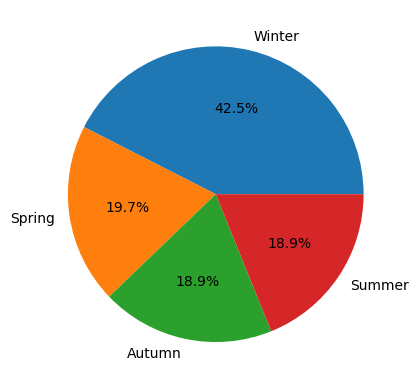

In [33]:
# Step 4: Visualize the distribution of key features

# Visualize season using a pie chart

plt.pie(df['season'].value_counts(),labels=df['season'].value_counts().index,autopct="%1.1f%%")
plt.show

Text(0, 0.5, 'Frequency')

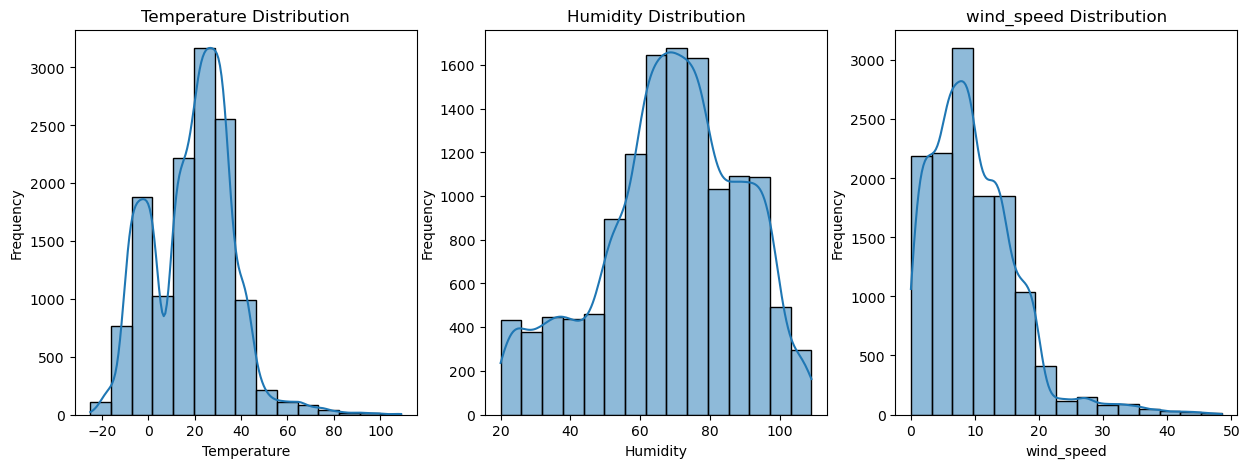

In [34]:
# Visualize temperature, humidity, and wind_speed using histograms
plt.figure(figsize=(15,5))


plt.subplot(1,3,1)
sns.histplot(data=df, x='temperature', bins=15,kde=True)
plt.title('Temperature Distribution')
plt.xlabel('Temperature')
plt.ylabel('Frequency')

plt.subplot(1,3,2)
sns.histplot(data=df, x='humidity', bins=15,kde=True)
plt.title('Humidity Distribution')
plt.xlabel('Humidity')
plt.ylabel('Frequency')

plt.subplot(1,3,3)
sns.histplot(data=df, x='wind_speed', bins=15,kde=True)
plt.title('wind_speed Distribution')
plt.xlabel('wind_speed')
plt.ylabel('Frequency')

<Axes: ylabel='precipitation (%)'>

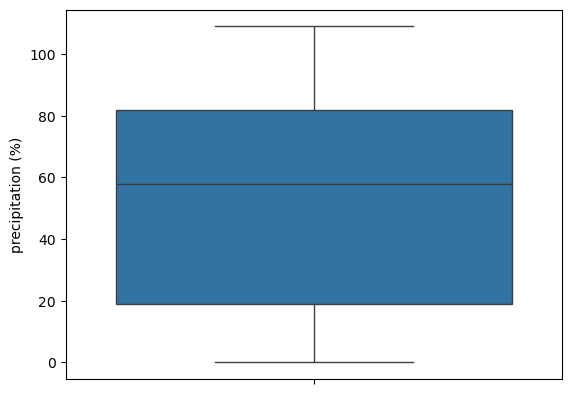

In [35]:
# Visualize precipitation (%) using a box plot
sns.boxplot(df['precipitation (%)'])

### Task 2: Data Transformation

1. Encode cloud_cover, location and season using one-hot encoding.
2. Scale the numerical features (temperature, humidity, wind_speed, precipitation (%), atmospheric_pressure, uv_index, visibility (km)) using StandardScaler.
3. Display the first few rows of the updated dataset.

In [36]:
# Step 1: Encode cloud_cover, location and season using one-hot encoding.

df=pd.get_dummies(data=df,columns=['cloud_cover','location','season'],drop_first=True,dtype=int)
df.head()

,temperature,humidity,wind_speed,precipitation (%),atmospheric_pressure,uv_index,visibility (km),weather_type,cloud_cover_cloudy,cloud_cover_overcast,cloud_cover_partly cloudy,location_inland,location_mountain,season_Spring,season_Summer,season_Winter
0,14,73,9.5,82,1010.82,2,3.5,Rainy,0,0,1,1,0,0,0,1
1,39,96,8.5,71,1011.43,7,10.0,Cloudy,0,0,1,1,0,1,0,0
2,30,64,7.0,16,1018.72,5,5.5,Sunny,0,0,0,0,1,1,0,0
3,38,83,1.5,82,1026.25,7,1.0,Sunny,0,0,0,0,0,1,0,0
4,27,74,17.0,66,990.67,1,2.5,Rainy,0,1,0,0,1,0,0,1


In [37]:
# Step 2: Scale the numerical features

scaler=StandardScaler()
numerical_features = ['temperature', 'humidity', 'wind_speed', 'precipitation (%)', 'atmospheric_pressure', 'uv_index', 'visibility (km)']
df[numerical_features] = scaler.fit_transform(df[numerical_features])


In [38]:
# Step3: Display the first few rows of the updated dataset.
df.head()


,temperature,humidity,wind_speed,precipitation (%),atmospheric_pressure,uv_index,visibility (km),weather_type,cloud_cover_cloudy,cloud_cover_overcast,cloud_cover_partly cloudy,location_inland,location_mountain,season_Spring,season_Summer,season_Winter
0,-0.294931,0.212404,-0.048086,0.887629,0.134203,-0.520104,-0.582231,Rainy,0,0,1,1,0,0,0,1
1,1.143035,1.351385,-0.192836,0.543291,0.150602,0.776424,1.345768,Cloudy,0,0,1,1,0,1,0,0
2,0.625367,-0.233285,-0.409962,-1.178401,0.346579,0.257813,0.010999,Sunny,0,0,0,0,1,1,0,0
3,1.085516,0.707613,-1.206089,0.887629,0.549008,0.776424,-1.323769,Sunny,0,0,0,0,0,1,0,0
4,0.452811,0.261924,1.037543,0.386773,-0.407490,-0.779410,-0.878846,Rainy,0,1,0,0,1,0,0,1


### Task 3: Model Training Using SVM with Linear Kernel

1. Select the features and the target variable for modeling.
2. Split the data into training and test sets with a test size of 30%.
3. Initialize and train an SVM model with a linear kernel using the training data.
4. Print the model's accuracy score on test data.
5. Evaluate the model using a classification report and confusion matrix.

In [49]:
# Step 1: Select features and target variable
X=df.drop("weather_type",axis=1)
y=df['weather_type']
# Step 2: Split the data
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=52)

In [50]:
# Step 3: Train SVM with linear kernel
lk=SVC(kernel='linear')
lk.fit(X_train,y_train)

y_pred=lk.predict(X_test)

# Step 4: Print accuracy score
lk.score(X_test,y_test)

0.8924242424242425

In [51]:
# Step 5: Evaluate the model


#classification report
report=classification_report(y_test,y_pred)
print(report)
lk.n_iter_






              precision    recall  f1-score   support

      Cloudy       0.88      0.85      0.87       986
       Rainy       0.87      0.88      0.88      1003
       Snowy       0.90      0.94      0.92       979
       Sunny       0.91      0.90      0.91       992

    accuracy                           0.89      3960
   macro avg       0.89      0.89      0.89      3960
weighted avg       0.89      0.89      0.89      3960



array([41477, 26199, 44357, 19428, 18641, 13347], dtype=int32)

<function matplotlib.pyplot.show(close=None, block=None)>

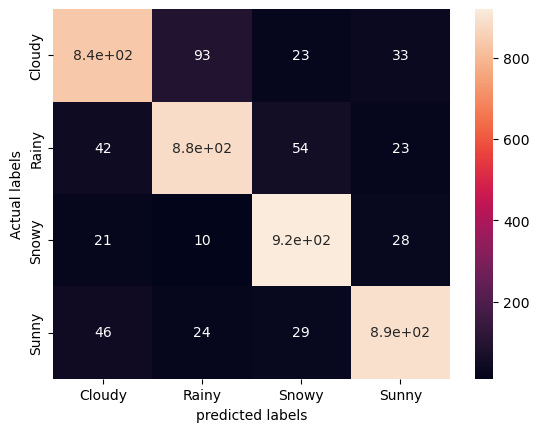

In [52]:
#confusion matrix

cm= confusion_matrix(y_test,y_pred)

classes=['Cloudy',"Rainy","Snowy","Sunny"]

sns.heatmap(cm,annot=True,xticklabels=classes,yticklabels=classes)
plt.xlabel("predicted labels")
plt.ylabel("Actual labels")
plt.show

### Task 4: Model Training Using SVM with RBF Kernel

1. Initialize and train an SVM model with an RBF kernel using the training data.
2. Print the model's accuracy score on test data.
3. Evaluate the model using a classification report and confusion matrix.

In [53]:
# Step 1: Train SVM with RBF kernel

model=SVC(kernel='rbf')
model.fit(X_train,y_train)

# Step 2: Print accuracy score

model.score(X_test,y_test)




0.9090909090909091

In [54]:
# Step 3: Evaluate the model

#classification report
y_pred=model.predict(X_test)
report=classification_report(y_test,y_pred)
print(report)



              precision    recall  f1-score   support

      Cloudy       0.88      0.89      0.89       986
       Rainy       0.89      0.92      0.91      1003
       Snowy       0.93      0.93      0.93       979
       Sunny       0.93      0.90      0.91       992

    accuracy                           0.91      3960
   macro avg       0.91      0.91      0.91      3960
weighted avg       0.91      0.91      0.91      3960



<function matplotlib.pyplot.show(close=None, block=None)>

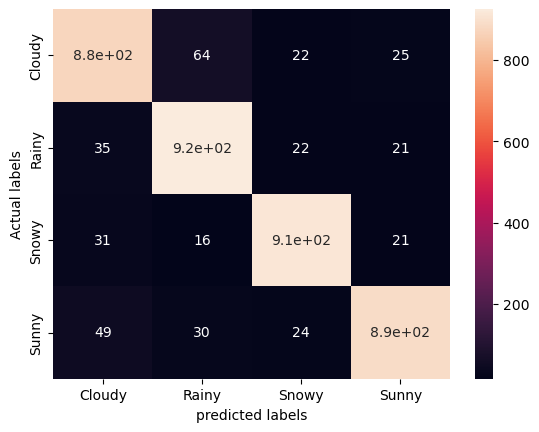

In [55]:
#confusion matrix
cm=confusion_matrix(y_test,y_pred)

classes=['Cloudy',"Rainy","Snowy","Sunny"]

sns.heatmap(cm,annot=True,xticklabels=classes,yticklabels=classes)
plt.xlabel("predicted labels")
plt.ylabel("Actual labels")
plt.show

### Task 5: Experiment with Hyperparameters in SVM

1. Train an SVM model with an RBF kernel and the following hyperparameters:
    - C=0.5
    - gamma='auto'
    - kernel='rbf'
    - degree=2
      
Learn about these parameters here: [SVC Parameters](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html)

--------------------------------------------------------------------------------------------------------------------------------------------------------

2. Print the model's accuracy score on test data.
3. Evaluate the model using a classification report and confusion matrix.

In [57]:
# Step 1: Train the SVM model with specified hyperparameters
model_h=SVC(C=0.5,gamma='auto',kernel="rbf",degree=2)
model_h.fit(X_train,y_train)


# Step 3: Make predictions on the test set
y_pred_h=model_h.predict(X_test)

# Step 2: Print the model's accuracy score
model_h.score(X_test,y_test)

0.9068181818181819

              precision    recall  f1-score   support

      Cloudy       0.88      0.88      0.88       986
       Rainy       0.89      0.92      0.91      1003
       Snowy       0.94      0.93      0.93       979
       Sunny       0.91      0.90      0.91       992

    accuracy                           0.91      3960
   macro avg       0.91      0.91      0.91      3960
weighted avg       0.91      0.91      0.91      3960



<Axes: >

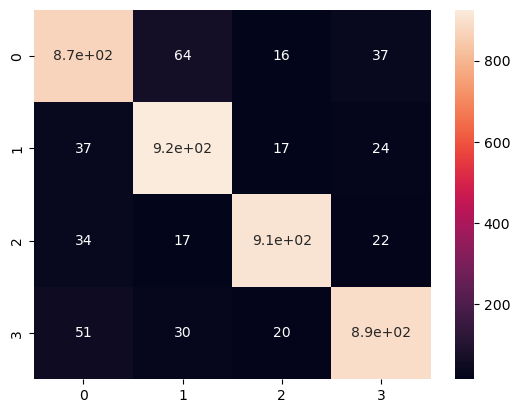

In [58]:
# Step 4: Evaluate the model using a classification report and confusion matrix


#classification report
report_h=classification_report(y_test,y_pred_h)
print(report_h)


#confusion matrix
cm_h=confusion_matrix(y_test,y_pred_h)

sns.heatmap(cm_h,annot=True)

### Task 6: Implementing Sklearn Pipeline

1. Create a pipeline that includes the StandardScaler and the SVM model with an RBF kernel.
2. Train the pipeline using the training data.
3. Evaluate the pipeline using the test data and print the classification report.

In [60]:
# Create a pipeline with two steps: scaling and SVM with RBF kernel
from sklearn.pipeline import Pipeline

pipe=Pipeline([
    ('scaler',StandardScaler()),
    ('svc',SVC(kernel='rbf'))
])
# Fit the pipeline on the training data
pipe.fit(X_train,y_train)

# Make predictions using the pipeline on the test data
y_pred_pipe=pipe.predict(X_test)

# Print the classification report for the pipeline model
print('Classification report for Pipeline')
report=classification_report(y_test,y_pred_pipe)
print(report)

# Print the confusion matrix for the pipeline model
print('Confusion Matrix report for Pipeline')
cm_pipe=confusion_matrix(y_test,y_pred_pipe)
print(cm_pipe)

Classification report for Pipeline
              precision    recall  f1-score   support

      Cloudy       0.88      0.88      0.88       986
       Rainy       0.90      0.93      0.91      1003
       Snowy       0.93      0.93      0.93       979
       Sunny       0.92      0.90      0.91       992

    accuracy                           0.91      3960
   macro avg       0.91      0.91      0.91      3960
weighted avg       0.91      0.91      0.91      3960

Confusion Matrix report for Pipeline
[[868  63  24  31]
 [ 33 928  23  19]
 [ 27  18 911  23]
 [ 54  27  19 892]]
